## Clone a group and its content to another organization

Clone a group and its contents from one organization to another within a desired folder.


#### Import necessary libraries and connect to GIS

In [1]:
from arcgis.gis import GIS
from arcgis.gis import ItemProperties

source_gis = GIS("home")

You are logged on as MMajumdar_geosaurus with an administrator role, proceed with caution.


#### Define variables

In [2]:
target_gis = GIS("<URL>", "<USERNAME>", "<PASSWORD>", verify_cert=False)
target_folder_name = "<FOLDER_NAME>"

source_group_id = "<GROUP_ID>"

Setting `verify_cert` to False is a security risk, use at your own risk.


#### Fetch the group to clone

<Group title:"My New Group" owner:MMajumdar_geosaurus>
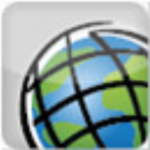

In [3]:
source_group = source_gis.groups.get(source_group_id)
source_group

#### Fetch items for this group

In [4]:
source_items = source_group.content()
source_items

[<Item title:"England temperatures 2024" type:Feature Layer Collection owner:MMajumdar_geosaurus>,
 <Item title:"pop25_with_bachelors_degree" type:Web Map owner:MMajumdar_geosaurus>]

#### Clone the group to the target organization

<Group title:"My New Group" owner:mmajumdar>
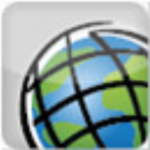

In [5]:
target_group_job = target_gis.groups.clone([source_group])
target_group = target_group_job[0].result()
target_group

#### Clone items from the original group to the cloned group

In [6]:
cloned_items = target_gis.content.clone_items(source_items, folder = target_folder_name)
cloned_items

[<Item title:"England temperatures 2024" type:Feature Layer Collection owner:mmajumdar>,
 <Item title:"US Counties pop 25 with bachelors degrees" type:Feature Layer Collection owner:mmajumdar>,
 <Item title:"pop25_with_bachelors_degree" type:Web Map owner:mmajumdar>]

#### Share the group with the cloned group in the target organization

In [10]:
for item in cloned_items:
    item.sharing.groups.add(target_group)

# Verify the share
print("Items shared with the newly cloned group: ")
target_gis.groups.get(target_group.id).content()

Items shared with the newly cloned group: 


[<Item title:"England temperatures 2024" type:Feature Layer Collection owner:mmajumdar>,
 <Item title:"pop25_with_bachelors_degree" type:Web Map owner:mmajumdar>,
 <Item title:"US Counties pop 25 with bachelors degrees" type:Feature Layer Collection owner:mmajumdar>]